In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV, LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from geopy.distance import geodesic

In [7]:
df = pd.read_csv(r"C:\Users\marti\OneDrive\Boston University Classes\DX799 - DS Capstone - Fall 2026\Datasets for capstone\Loan_approval_data_2025.csv", sep=",")
df

,customer_id,age,occupation_status,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,product_type,loan_intent,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
0,CUST100000,40,Employed,17.2,25579,692,5.3,895,10820,0,0,0,Credit Card,Business,600,17.02,0.423,0.023,0.008,1
1,CUST100001,33,Employed,7.3,43087,627,3.5,169,16550,0,1,0,Personal Loan,Home Improvement,53300,14.10,0.384,1.237,0.412,0
2,CUST100002,42,Student,1.1,20840,689,8.4,17,7852,0,0,0,Credit Card,Debt Consolidation,2100,18.33,0.377,0.101,0.034,1
3,CUST100003,53,Student,0.5,29147,692,9.8,1480,11603,0,1,0,Credit Card,Business,2900,18.74,0.398,0.099,0.033,1
4,CUST100004,32,Employed,12.5,63657,630,7.2,209,12424,0,0,0,Personal Loan,Education,99600,13.92,0.195,1.565,0.522,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,CUST149995,35,Employed,4.3,39449,570,16.3,1127,7576,0,0,0,Credit Card,Education,42800,21.31,0.192,1.085,0.362,0
49996,CUST149996,34,Employed,4.4,20496,672,12.6,1478,6276,1,0,0,Credit Card,Personal,3800,18.07,0.306,0.185,0.062,0
49997,CUST149997,41,Self-Employed,4.8,18743,719,10.1,17,10331,0,0,0,Credit Card,Personal,18000,17.45,0.551,0.960,0.320,0
49998,CUST149998,38,Student,0.4,17250,633,1.3,5,7779,0,0,1,Personal Loan,Personal,1400,14.71,0.451,0.081,0.027,0


#### Regression — Predict loan_amount
#### Classification — Predict loan_status

### EDA

In [8]:
df.describe()

,age,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,34.957060,7.454868,50062.892040,643.614820,8.168274,3595.619400,14290.442220,0.053480,0.55464,0.147640,33041.874000,15.498591,0.285724,0.701999,0.233995,0.550460
std,11.118603,7.612097,32630.501014,64.731518,7.207552,13232.399398,13243.757493,0.224991,0.84505,0.412996,26116.185102,4.067942,0.159787,0.465788,0.155268,0.497452
min,18.000000,0.000000,15000.000000,348.000000,0.000000,0.000000,60.000000,0.000000,0.00000,0.000000,500.000000,6.000000,0.002000,0.008000,0.003000,0.000000
25%,26.000000,1.300000,27280.500000,600.000000,2.000000,130.000000,5581.000000,0.000000,0.00000,0.000000,12300.000000,12.180000,0.161000,0.333000,0.111000,0.000000
50%,35.000000,4.900000,41607.500000,643.000000,6.100000,568.000000,10385.000000,0.000000,0.00000,0.000000,26100.000000,15.440000,0.265000,0.622000,0.207000,1.000000
75%,43.000000,11.400000,62723.250000,687.000000,12.600000,2271.000000,18449.250000,0.000000,1.00000,0.000000,48500.000000,18.870000,0.389000,1.010250,0.337000,1.000000
max,70.000000,39.900000,250000.000000,850.000000,30.000000,300000.000000,163344.000000,1.000000,9.00000,4.000000,100000.000000,23.000000,0.800000,2.001000,0.667000,1.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              50000 non-null  object 
 1   age                      50000 non-null  int64  
 2   occupation_status        50000 non-null  object 
 3   years_employed           50000 non-null  float64
 4   annual_income            50000 non-null  int64  
 5   credit_score             50000 non-null  int64  
 6   credit_history_years     50000 non-null  float64
 7   savings_assets           50000 non-null  int64  
 8   current_debt             50000 non-null  int64  
 9   defaults_on_file         50000 non-null  int64  
 10  delinquencies_last_2yrs  50000 non-null  int64  
 11  derogatory_marks         50000 non-null  int64  
 12  product_type             50000 non-null  object 
 13  loan_intent              50000 non-null  object 
 14  loan_amount           

In [10]:
df.isnull().sum().sort_values(ascending=False)

customer_id                0
age                        0
payment_to_income_ratio    0
loan_to_income_ratio       0
debt_to_income_ratio       0
interest_rate              0
loan_amount                0
loan_intent                0
product_type               0
derogatory_marks           0
delinquencies_last_2yrs    0
defaults_on_file           0
current_debt               0
savings_assets             0
credit_history_years       0
credit_score               0
annual_income              0
years_employed             0
occupation_status          0
loan_status                0
dtype: int64

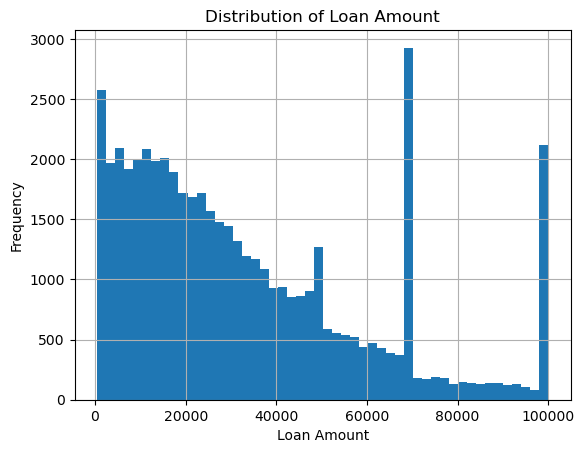

In [11]:
df["loan_amount"].hist(bins = 50)
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Loan Amount")
plt.show()

In [12]:
# Check for imbalance
df["loan_status"].value_counts(normalize=True) 

loan_status
1    0.55046
0    0.44954
Name: proportion, dtype: float64

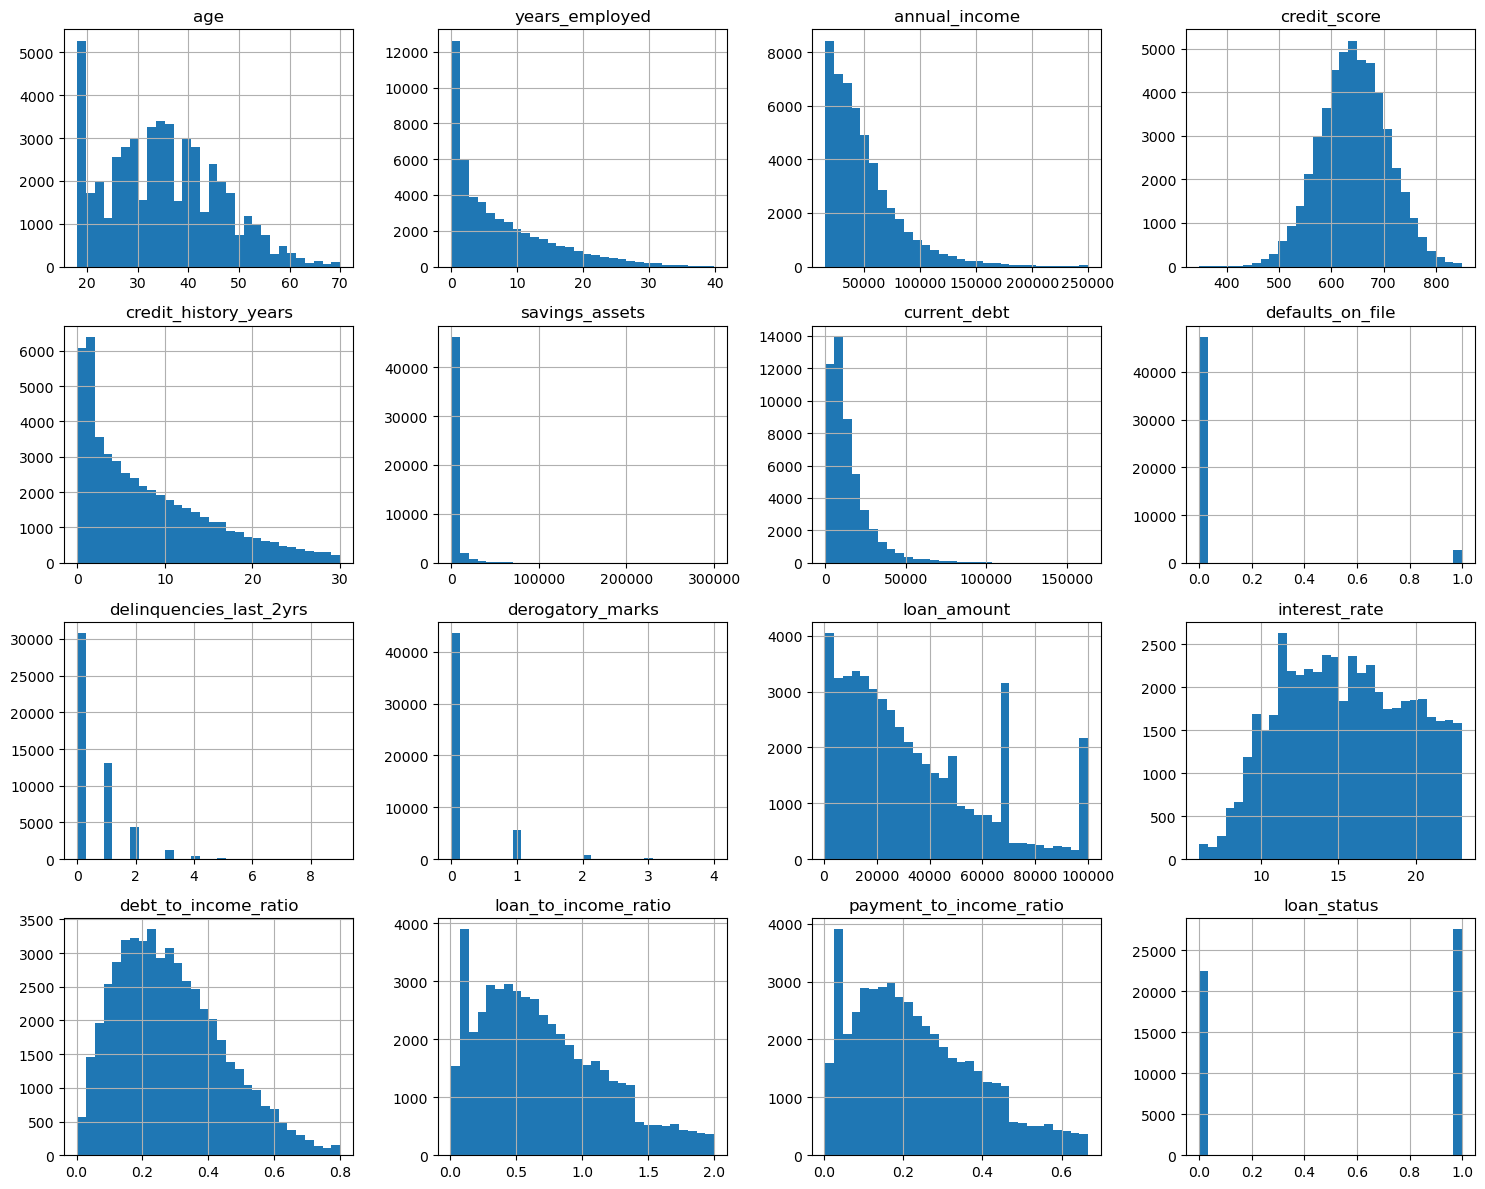

In [13]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
df[num_cols].hist(figsize = (15, 12), bins = 30)
plt.tight_layout()
plt.show()

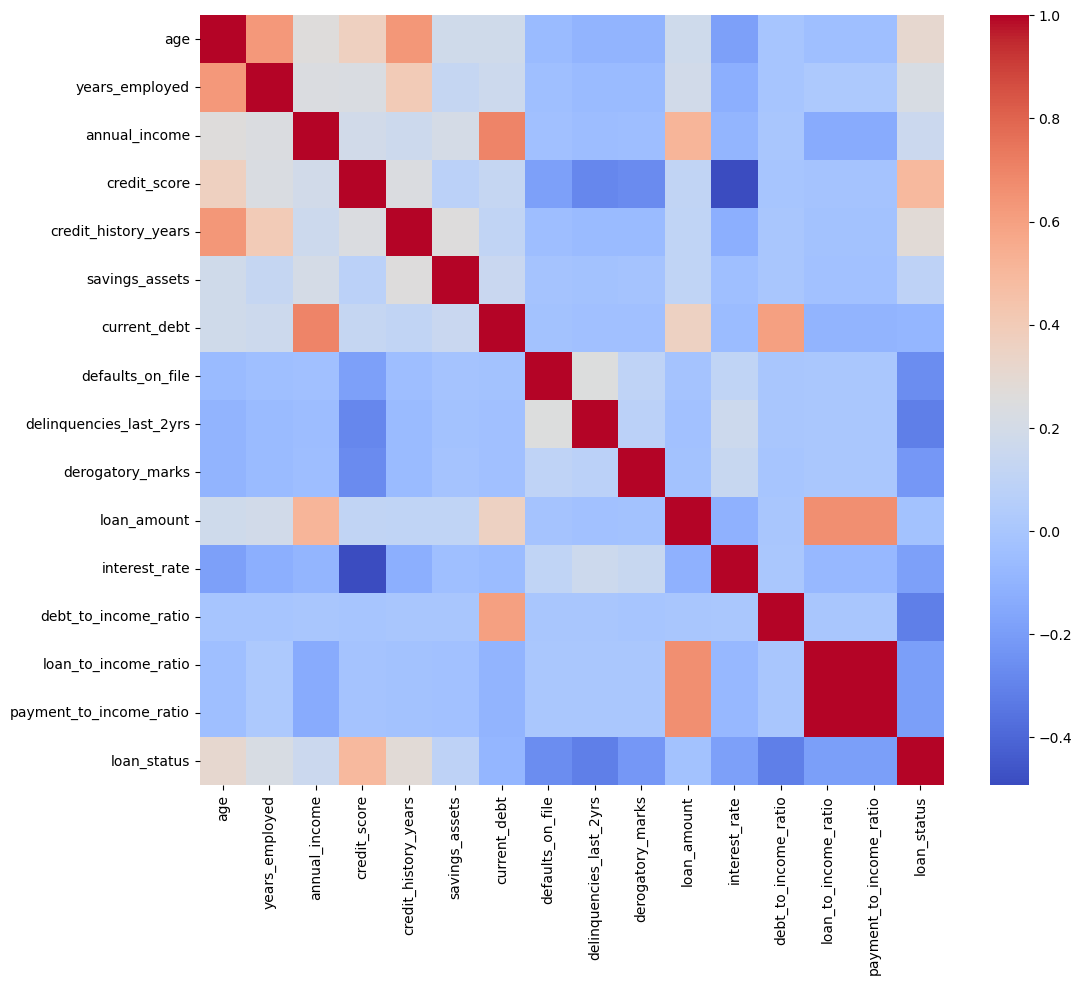

In [14]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True),
            cmap = "coolwarm")
plt.show()

In [15]:
df.corr(numeric_only=True)["loan_amount"].sort_values(ascending=False)

loan_amount                1.000000
payment_to_income_ratio    0.662176
loan_to_income_ratio       0.662174
annual_income              0.511129
current_debt               0.359800
years_employed             0.185206
age                        0.172352
credit_score               0.112019
credit_history_years       0.107280
savings_assets             0.106962
debt_to_income_ratio      -0.001320
defaults_on_file          -0.019340
derogatory_marks          -0.024051
loan_status               -0.025987
delinquencies_last_2yrs   -0.029398
interest_rate             -0.110787
Name: loan_amount, dtype: float64

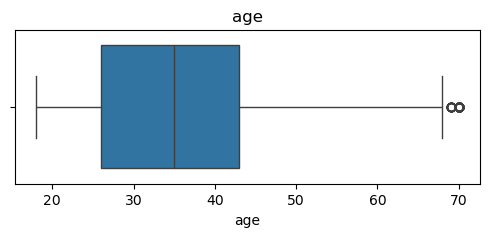

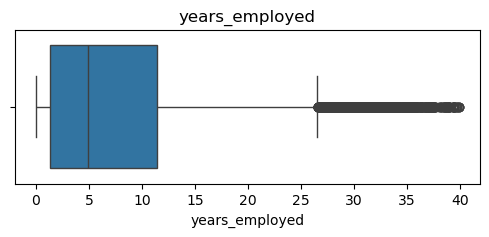

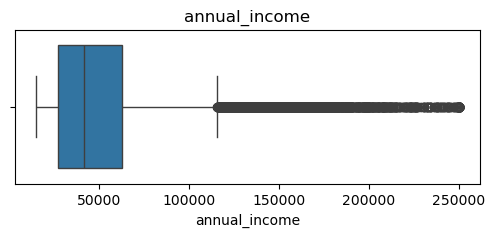

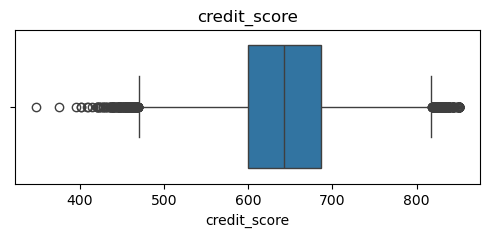

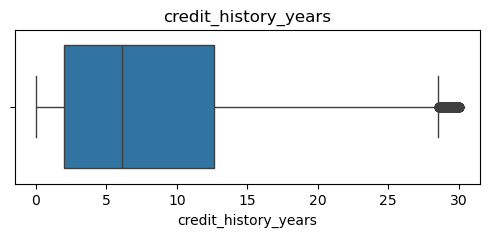

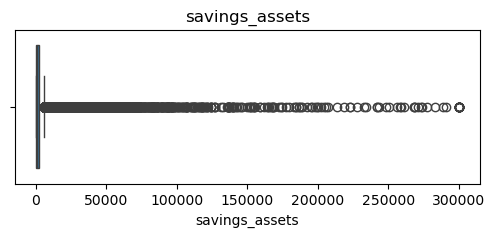

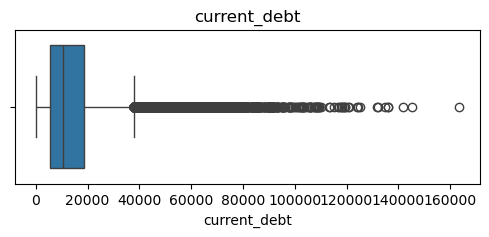

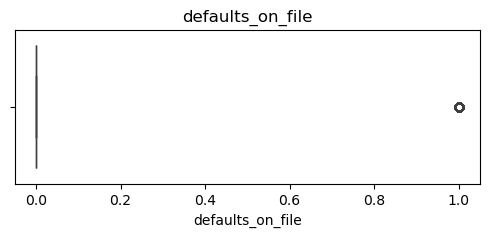

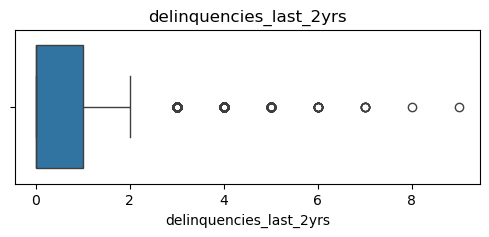

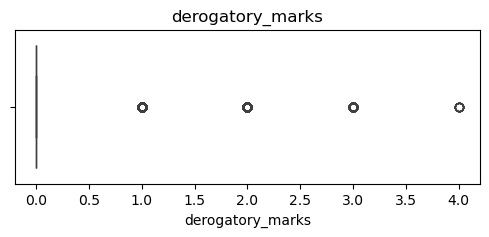

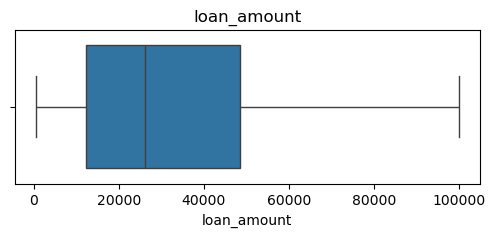

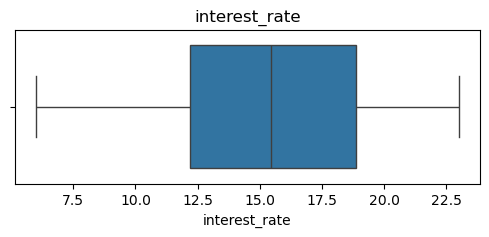

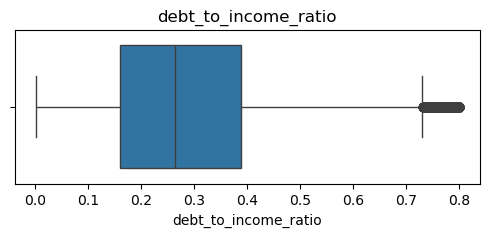

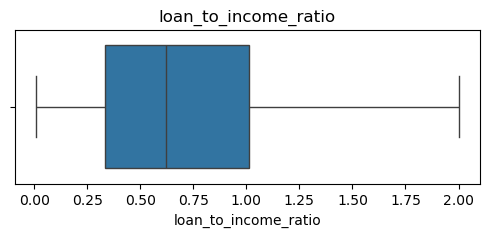

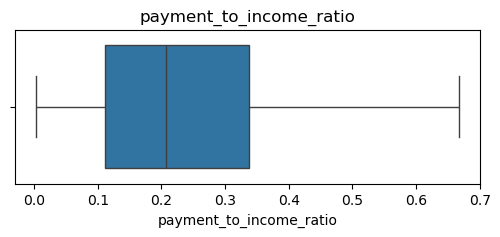

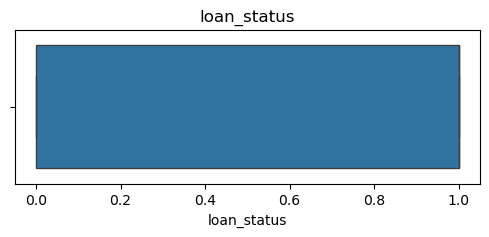

In [16]:
for col in num_cols:
    plt.figure(figsize=(6, 2))
    sns.boxplot(x = df[col])
    plt.title(col)
    plt.show()

## Week 1 - Linear Regression & Feature Engineering

#### Feature Engineering

In [17]:
## Feature Engineering ##

# Polynomial Terms
df["credit_score_sq"] = df["credit_score"] ** 2
df["annual_income_sq"] = df["annual_income"] ** 2
df["years_employed_sq"] = df["years_employed"] ** 2

# Interaction Terms
#df["dti_interact"] = (df["debt_to_income_ratio"] * df["annual_income"])
df["credit_income_interact"] = (df["credit_score"] * df["annual_income"])
df["employed_income_interact"] = (df["years_employed"] * df["annual_income"])

# Encode Categoricals
df = pd.get_dummies(
    df, 
    columns = [
        "occupation_status",
        "product_type",
        "loan_intent"
        ],
        drop_first=True
)

In [18]:
X = df.drop(["customer_id", "loan_amount", "loan_status", "loan_to_income_ratio", "payment_to_income_ratio"], axis = 1)
X = X.astype(float)
y = df["loan_amount"]


In [19]:
X.head()

,age,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,...,employed_income_interact,occupation_status_Self-Employed,occupation_status_Student,product_type_Line of Credit,product_type_Personal Loan,loan_intent_Debt Consolidation,loan_intent_Education,loan_intent_Home Improvement,loan_intent_Medical,loan_intent_Personal
0,40.0,17.2,25579.0,692.0,5.3,895.0,10820.0,0.0,0.0,0.0,...,439958.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,33.0,7.3,43087.0,627.0,3.5,169.0,16550.0,0.0,1.0,0.0,...,314535.1,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,42.0,1.1,20840.0,689.0,8.4,17.0,7852.0,0.0,0.0,0.0,...,22924.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,53.0,0.5,29147.0,692.0,9.8,1480.0,11603.0,0.0,1.0,0.0,...,14573.5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,32.0,12.5,63657.0,630.0,7.2,209.0,12424.0,0.0,0.0,0.0,...,795712.5,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [20]:
y.describe()

count     50000.000000
mean      33041.874000
std       26116.185102
min         500.000000
25%       12300.000000
50%       26100.000000
75%       48500.000000
max      100000.000000
Name: loan_amount, dtype: float64

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.20, random_state = 42
)

In [22]:
lr = LinearRegression()
lr.fit(X_train, y_train)

y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

# Cross validation
cv_lr = -cross_val_score(
    lr, X_train, y_train, cv = 5, scoring = "neg_root_mean_squared_error"
)

print("Train: RMSE:", root_mean_squared_error(y_train, y_train_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_test_pred))
print("CV RMSE:", cv_lr.mean())

print("Train MAE:", mean_absolute_error(y_train, y_train_pred))
print("Test MAE:", mean_absolute_error(y_test, y_test_pred))

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))

Train: RMSE: 19407.686348169762
Test RMSE: 19438.551482180294
CV RMSE: 19425.77956390451
Train MAE: 15159.78500668766
Test MAE: 15192.426098958378
Train R2: 0.44661386452080354
Test R2: 0.45043579558048996


In [23]:
vif_data = pd.DataFrame()
vif_data["Feature"] = X_train.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

print(vif_data.sort_values(by = "VIF", ascending = False))

                            Feature         VIF
15           credit_income_interact  131.104445
2                     annual_income  116.790660
12                  credit_score_sq   86.171375
3                      credit_score   44.083869
10                    interest_rate   19.204941
19      product_type_Line of Credit   12.927427
13                 annual_income_sq   12.324102
1                    years_employed   12.108259
20       product_type_Personal Loan   10.660390
14                years_employed_sq    8.841109
16         employed_income_interact    6.682068
6                      current_debt    6.631071
11             debt_to_income_ratio    3.407438
0                               age    2.681205
25             loan_intent_Personal    2.004622
22            loan_intent_Education    1.884876
4              credit_history_years    1.756847
24              loan_intent_Medical    1.717307
23     loan_intent_Home Improvement    1.695229
21   loan_intent_Debt Consolidation    1

## Week 2 Linear regression 2 (ridge, lasso, elastic net)

### Feature Scaling

In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Ridge Regression

In [25]:
print("Ridge Regression\n")

alphas = np.logspace(-3, 3, 100)

ridge_cv = RidgeCV(alphas = alphas, cv = 5)
ridge_cv.fit(X_train_scaled, y_train)

print("Best Alpha:", ridge_cv.alpha_)


ridge = Ridge(alpha = ridge_cv.alpha_)
ridge.fit(X_train_scaled, y_train)
ridge_pred = ridge.predict(X_test_scaled)

print("\nRMSE:", root_mean_squared_error(y_test, ridge_pred))
print("MAE:", mean_absolute_error(y_test, ridge_pred))
print("R2:", r2_score(y_test, ridge_pred))

Ridge Regression

Best Alpha: 1.873817422860385

RMSE: 19438.17235703271
MAE: 15191.955413714733
R2: 0.45045723252536285


### Lasso Regression

In [26]:
print("Lasso Regression\n")
lasso_cv = LassoCV(
    cv = 5,
    random_state = 42,
    max_iter = 10000
)

lasso_cv.fit(X_train_scaled, y_train)
print("Best Alpha:", lasso_cv.alpha_)

lasso = Lasso(alpha = lasso_cv.alpha_)
lasso.fit(X_train_scaled, y_train)
lasso_pred = lasso.predict(X_test_scaled)

print("\nRMSE:", root_mean_squared_error(y_test, lasso_pred))
print("MAE:", mean_absolute_error(y_test, lasso_pred))
print("R2:", r2_score(y_test, lasso_pred))

Lasso Regression

Best Alpha: 46.45432868416932

RMSE: 19433.694555597824
MAE: 15180.611846165126
R2: 0.4507103900668836


### Elastic Net

In [27]:
print("Elastic Net Regression\n")

elastic_cv = ElasticNetCV(
    cv = 5,
    random_state = 42, 
    max_iter = 10000
)
elastic_cv.fit(X_train_scaled, y_train)
print("Best Alpha:", elastic_cv.alpha_)
print("Best L1 Ratio:", elastic_cv.l1_ratio_)

elastic = ElasticNet(
    alpha = elastic_cv.alpha_,
    l1_ratio = elastic_cv.l1_ratio_
)
elastic.fit(X_train_scaled, y_train)
elastic_pred = elastic.predict(X_test_scaled)

print("\nRMSE:", root_mean_squared_error(y_test, elastic_pred))
print("MAE:", mean_absolute_error(y_test, elastic_pred))
print("R2:", r2_score(y_test, elastic_pred))

Elastic Net Regression

Best Alpha: 26.460718867324086
Best L1 Ratio: 0.5

RMSE: 24456.870275355108
MAE: 19963.10790964803
R2: 0.13005379264160655


## Week 3: Forward and Backward Selection, PCR, PLSR

In [28]:
lr = LinearRegression()

### Forward Selection

In [29]:
forward_selection = SequentialFeatureSelector(
    lr,
    n_features_to_select = "auto",
    direction = "forward",
    scoring = "neg_root_mean_squared_error",
    cv = 5,
    n_jobs = -1
)

forward_selection.fit(X_train_scaled, y_train)
forward_features = X_train.columns[forward_selection.get_support()]
print(forward_selection)

SequentialFeatureSelector(estimator=LinearRegression(), n_jobs=-1,
                          scoring='neg_root_mean_squared_error')


In [30]:
X_train_forward = X_train[forward_features]
X_test_forward = X_test[forward_features]

lr_forward = LinearRegression()
lr_forward.fit(X_train_forward, y_train)

forward_pred = lr_forward.predict(X_test_forward)

forward_rmse = root_mean_squared_error(y_test, forward_pred)
forward_mae = mean_absolute_error(y_test, forward_pred)
forward_r2 = r2_score(y_test, forward_pred)

print(forward_rmse, forward_mae, forward_r2)

19433.75304748644 15184.717660036915 0.4507070835381184


### Backward Selection

In [31]:
backward_selection = SequentialFeatureSelector(
    lr,
    n_features_to_select = "auto",
    direction = "backward",
    scoring = "neg_root_mean_squared_error",
    cv = 5,
    n_jobs = -1
)

backward_selection.fit(X_train_scaled, y_train)
backward_features = X_train.columns[backward_selection.get_support()]
print(backward_selection)

SequentialFeatureSelector(direction='backward', estimator=LinearRegression(),
                          n_jobs=-1, scoring='neg_root_mean_squared_error')


In [32]:
X_train_backward = X_train[backward_features]
X_test_backward = X_test[backward_features]

lr_backward = LinearRegression()
lr_backward.fit(X_train_backward, y_train)

backward_pred = lr_backward.predict(X_test_backward)

backward_rmse = root_mean_squared_error(y_test, backward_pred)
backward_mae = mean_absolute_error(y_test, backward_pred)
backward_r2 = r2_score(y_test, backward_pred)

print(backward_rmse, backward_mae, backward_r2)

19438.989229144212 15192.813912101015 0.4504110434510994


#### Principal Component Regression (PCR)

#### Start with PCA

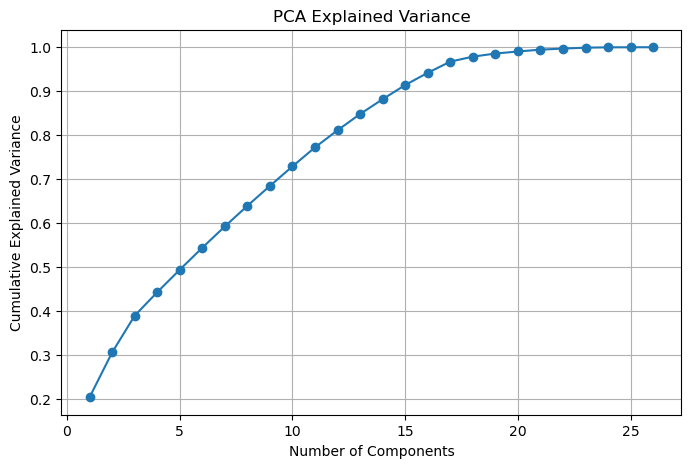

In [33]:
pca = PCA()
pca.fit(X_train_scaled)

var = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize = (8, 5))
plt.plot(
    range(1, len(var) + 1),
    var,
    marker = "o"
)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title ("PCA Explained Variance")
plt.grid()
plt.show()

In [34]:
pcr = make_pipeline(
    PCA(n_components = 20), 
    LinearRegression()
)
pcr.fit(X_train_scaled, y_train)
pcr_pred = pcr.predict(X_test_scaled)

pcr_rmse = root_mean_squared_error(y_test, pcr_pred)
pcr_mae = mean_absolute_error(y_test, pcr_pred)
pcr_r2 = r2_score(y_test, pcr_pred)

print(pcr_rmse, pcr_mae, pcr_r2)

20617.278147314344 16114.69269243703 0.38176541116010865


#### Partial Least Squares Regression (PLS)

In [35]:
pls = PLSRegression(n_components=10)
pls.fit(X_train_scaled, y_train)
pls_pred = pls.predict(X_test_scaled)

pls_rmse = root_mean_squared_error(y_test, pls_pred)
pls_mae = mean_absolute_error(y_test, pls_pred)
pls_r2 = r2_score(y_test, pls_pred)

print(pls_rmse, pls_mae, pls_r2)

19455.628975176307 15200.067490293095 0.4494697460808247


In [36]:
print("Comparison Table between selection models")
res = pd.DataFrame({
    "Model": ["Foward Selection", "Backward Selection", "Principal Component Regression", "Partial Least Squares Regression"],
    "RMSE": [
        forward_rmse,
        backward_rmse,
        pcr_rmse,
        pls_rmse
    ],
    "MAE":[
        forward_mae,
        backward_mae,
        pcr_mae,
        pls_mae
    ],
    "R2 Score":[
        forward_r2,
        backward_r2,
        pcr_r2,
        pls_r2
    ]
})
res

Comparison Table between selection models


,Model,RMSE,MAE,R2 Score
0,Foward Selection,19433.753047,15184.717660,0.450707
1,Backward Selection,19438.989229,15192.813912,0.450411
2,Principal Component Regression,20617.278147,16114.692692,0.381765
3,Partial Least Squares Regression,19455.628975,15200.067490,0.449470


### Week 4 Logistic Regression and Feature Scaling

In [37]:
X = df.drop(columns = ["customer_id", "loan_status"])
y = df["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
X.head()

,age,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,...,employed_income_interact,occupation_status_Self-Employed,occupation_status_Student,product_type_Line of Credit,product_type_Personal Loan,loan_intent_Debt Consolidation,loan_intent_Education,loan_intent_Home Improvement,loan_intent_Medical,loan_intent_Personal
0,40,17.2,25579,692,5.3,895,10820,0,0,0,...,439958.8,False,False,False,False,False,False,False,False,False
1,33,7.3,43087,627,3.5,169,16550,0,1,0,...,314535.1,False,False,False,True,False,False,True,False,False
2,42,1.1,20840,689,8.4,17,7852,0,0,0,...,22924.0,False,True,False,False,True,False,False,False,False
3,53,0.5,29147,692,9.8,1480,11603,0,1,0,...,14573.5,False,True,False,False,False,False,False,False,False
4,32,12.5,63657,630,7.2,209,12424,0,0,0,...,795712.5,False,False,False,True,False,True,False,False,False


In [39]:
y.value_counts(normalize=True)

loan_status
1    0.55046
0    0.44954
Name: proportion, dtype: float64

In [40]:
log_reg = LogisticRegression(max_iter = 1000, random_state = 42)
log_reg.fit(X_train_scaled, y_train)

log_pred = log_reg.predict(X_test_scaled)
log_prob = log_reg.predict_proba(X_test_scaled)[:, 1]

log_matrix = confusion_matrix(y_test, log_pred)
log_report = classification_report(y_test, log_pred)
log_roc_auc = roc_auc_score(y_test, log_prob)

print("Log Matrix")
print(log_matrix)
print("\nlog_report")
print(log_report)
print("\nlog_roc_auc")
print(log_roc_auc)

Log Matrix
[[3781  714]
 [ 601 4904]]

log_report
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      4495
           1       0.87      0.89      0.88      5505

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000


log_roc_auc
0.9474408440501556


In [41]:
print("unique y_test:", np.unique(y_test))
print("unique preds:", np.unique (log_pred))
print(confusion_matrix(y_test, log_pred))


unique y_test: [0 1]
unique preds: [0 1]
[[3781  714]
 [ 601 4904]]


In [42]:
print(pd.Series(log_pred).value_counts())
print(y_test.value_counts())

1    5618
0    4382
Name: count, dtype: int64
loan_status
1    5505
0    4495
Name: count, dtype: int64


Cross val for logisitc regression

In [43]:
log_cv = cross_val_score(
    log_reg,
    X_train_scaled,
    y_train,
    cv = 5,
    scoring = "roc_auc"
)

log_cv_auc_score = log_cv.mean()
print(log_cv_auc_score)

0.9484309562347379


### Week 5: Support Vector machiens

#### Base SVC

In [44]:
linear_svm = SVC(
    kernel = "linear",
    C = 1,
    probability = True,
    random_state = 42
)

linear_svm.fit(X_train_scaled, y_train)

svm_pred = linear_svm.predict(X_test_scaled)
svm_prob = linear_svm.predict_proba(X_test_scaled)[:,1]

svm_matrix = confusion_matrix(y_test, svm_pred)
svm_report = classification_report(y_test, svm_pred)
svm_roc_auc = roc_auc_score(y_test, svm_prob)

print("Confusion Matrix\n", svm_matrix)
print("\n Classificatin Report\n", svm_report)
print("\n ROC AUC Score:", svm_roc_auc)

Confusion Matrix
 [[3763  732]
 [ 585 4920]]

 Classificatin Report
               precision    recall  f1-score   support

           0       0.87      0.84      0.85      4495
           1       0.87      0.89      0.88      5505

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000


 ROC AUC Score: 0.947528356767384


#### Kernel Trick

In [45]:
rbf_svm = SVC(
    kernel = "rbf",
    C = 1,
    probability = True,
    random_state = 42
)
rbf_svm.fit(X_train_scaled, y_train)

rbf_pred = rbf_svm.predict(X_test_scaled)
rbf_prob = rbf_svm.predict_proba(X_test_scaled)[:,1]

rbf_matrix = confusion_matrix(y_test, rbf_pred)
rbf_report = classification_report(y_test, rbf_pred)
rbf_roc_auc = roc_auc_score(y_test, rbf_prob)


print("Confusion Matrix\n", rbf_matrix)
print("\n Classificatin Report\n", rbf_report)
print("\n ROC AUC Score:", rbf_roc_auc)

Confusion Matrix
 [[3992  503]
 [ 411 5094]]

 Classificatin Report
               precision    recall  f1-score   support

           0       0.91      0.89      0.90      4495
           1       0.91      0.93      0.92      5505

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000


 ROC AUC Score: 0.9728603888264183


Find the best Regularization (c) values and rerun rbf model afterwards

In [46]:
"""
c_values = [0.01, 0.1, 1, 10]

for c in c_values:
    svm = SVC(
        kernel = "rbf",
        C = c,
        probability = True,
        random_state = 42
    )
    svm.fit(X_train_scaled, y_train)
    prob = svm.predict_proba(X_test_scaled)[:,1]
    auc = roc_auc_score(y_test, prob)
    print(f"C = {c}, ROC AUC Score = {auc:.4f}")
"""


'\nc_values = [0.01, 0.1, 1, 10]\n\nfor c in c_values:\n    svm = SVC(\n        kernel = "rbf",\n        C = c,\n        probability = True,\n        random_state = 42\n    )\n    svm.fit(X_train_scaled, y_train)\n    prob = svm.predict_proba(X_test_scaled)[:,1]\n    auc = roc_auc_score(y_test, prob)\n    print(f"C = {c}, ROC AUC Score = {auc:.4f}")\n'

### Week 6: Decision Trees and Random Forest

In [47]:
tree = DecisionTreeClassifier(random_state = 42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
tree_prob = tree.predict_proba(X_test)[:,1]

print("Confusion Matrix")
print(confusion_matrix(y_test, tree_pred))
print("\n Classification Report\n")
print(classification_report(y_test, tree_pred))
print("\n ROC AUC Score:", roc_auc_score(y_test, tree_prob))

Confusion Matrix
[[3823  672]
 [ 595 4910]]

 Classification Report

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4495
           1       0.88      0.89      0.89      5505

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000


 ROC AUC Score: 0.8712084978869448


Tune Decision Tree

In [48]:
param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", None]
}

grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid = param_grid,
    cv = 5,
    scoring = "roc_auc",
    n_jobs = -1
)

grid_tree.fit(X_train, y_train)

print(grid_tree.best_params_)
print(grid_tree.best_score_)
print(grid_tree.best_estimator_)

{'max_depth': 10, 'max_features': None, 'min_samples_leaf': 10, 'min_samples_split': 2}
0.9496698774878067
DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=42)


Make Final Tree

In [49]:
best_tree = grid_tree.best_estimator_
tree_pred = best_tree.predict(X_test)
tree_prob = best_tree.predict_proba(X_test)[:,1]

print("Tree Confusion Matrix\n", confusion_matrix(y_test, tree_pred))
print("\nTree Classificatin Report\n", classification_report(y_test, tree_pred))
print("\nROC AUC Score", roc_auc_score(y_test, tree_prob))

Tree Confusion Matrix
 [[3899  596]
 [ 492 5013]]

Tree Classificatin Report
               precision    recall  f1-score   support

           0       0.89      0.87      0.88      4495
           1       0.89      0.91      0.90      5505

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000


ROC AUC Score 0.9536514989406941


In [50]:
importance = pd.DataFrame({
    "Features": X_train.columns,
    "Importance": best_tree.feature_importances_
})

importance.sort_values(by = "Importance", ascending = False).head(10)

,Features,Importance
15,credit_score_sq,0.327269
12,debt_to_income_ratio,0.239897
3,credit_score,0.087007
4,credit_history_years,0.062639
13,loan_to_income_ratio,0.059822
7,defaults_on_file,0.052597
8,delinquencies_last_2yrs,0.038587
25,loan_intent_Education,0.032095
24,loan_intent_Debt Consolidation,0.018600
11,interest_rate,0.016966


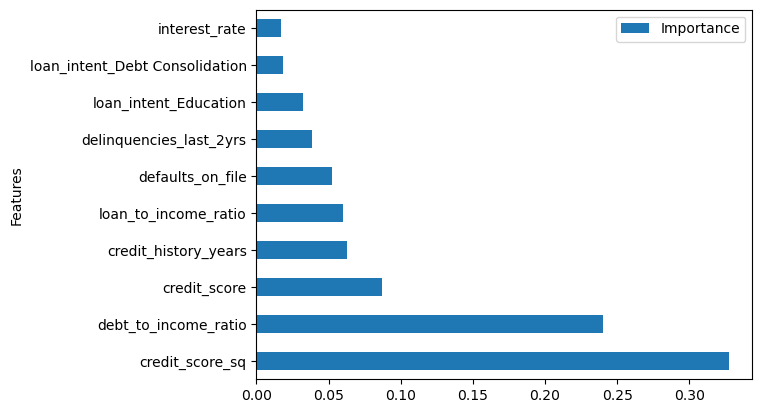

In [51]:
importance.sort_values(
    by = "Importance",
    ascending= False
).head(10).plot(
    kind = "barh",
    x = "Features",
    y = "Importance"
)
plt.show()

### Random Forest

#### Baseline forest

In [52]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:,1]

print("confusion matrix\n", confusion_matrix(y_test, rf_pred))
print("\nClassificatin Report\n", classification_report(y_test, rf_pred))
print("\nROC AUC Score:", roc_auc_score(y_test, rf_prob))

confusion matrix
 [[4021  474]
 [ 451 5054]]

Classificatin Report
               precision    recall  f1-score   support

           0       0.90      0.89      0.90      4495
           1       0.91      0.92      0.92      5505

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000


ROC AUC Score: 0.9710134077726891


Tune Random Forest

In [53]:
param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [5, 10, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2"]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)

print(grid_rf.best_params_)
print(grid_rf.best_score_)
print(grid_rf.best_estimator_)

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
0.9717420042879201
RandomForestClassifier(n_estimators=500, random_state=42)


Best Random Forest model

In [54]:
best_rf = grid_rf.best_estimator_
rf_pred = best_rf.predict(X_test)
rf_prob = best_rf.predict_proba(X_test)[:,1]

print("confusion matrix\n", confusion_matrix(y_test, rf_pred))
print("\nClassificatin Report\n", classification_report(y_test, rf_pred))
print("\nROC AUC Score:", roc_auc_score(y_test, rf_prob))

confusion matrix
 [[4023  472]
 [ 435 5070]]

Classificatin Report
               precision    recall  f1-score   support

           0       0.90      0.89      0.90      4495
           1       0.91      0.92      0.92      5505

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000


ROC AUC Score: 0.971991970086856


Feature importance

In [55]:
rf_importance = pd.DataFrame({
    "Features": X_train.columns,
    "Importance": best_rf.feature_importances_
})

rf_importance.sort_values(by = "Importance", ascending = False).head(10)

,Features,Importance
12,debt_to_income_ratio,0.163152
3,credit_score,0.135845
15,credit_score_sq,0.130719
4,credit_history_years,0.052965
8,delinquencies_last_2yrs,0.047843
11,interest_rate,0.039833
13,loan_to_income_ratio,0.039807
14,payment_to_income_ratio,0.037393
7,defaults_on_file,0.035477
6,current_debt,0.034604


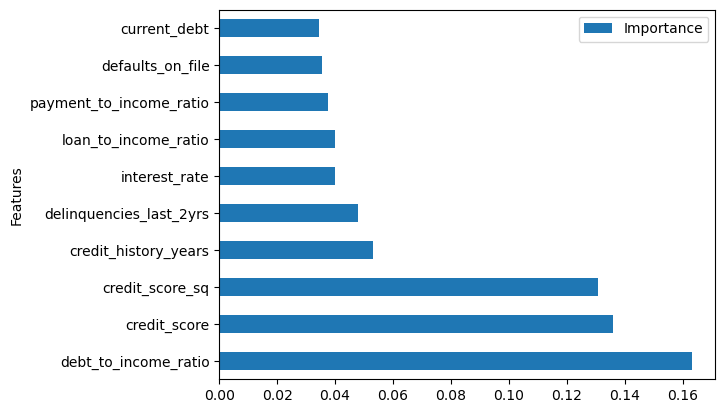

In [56]:
rf_importance.sort_values(
    by = "Importance",
    ascending= False
).head(10).plot(
    kind = "barh",
    x = "Features",
    y = "Importance"
)
plt.show()